# ResNet18 Ensemble — Multi-Resolution Classification

## 1. Experiment Setup

### Objective
Combine two fine-tuned ResNet18 models trained at different
image resolutions.

### Models
- ResNet18 — 384×288, best checkpoint
- ResNet18 — 512×384, best checkpoint

### Ensemble Method
Soft voting: average the predicted class probabilities
from both models.

### Evaluation
- Accuracy
- Macro-F1
- Per-class recall
- Confusion matrix
- Driver-specific accuracy

No additional training is performed.
The final test dataset remains untouched.

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import time

from pathlib import Path
from PIL import Image

from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# 2. CONFIGURATION
# ============================================================

ROOT = Path("..")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE = 32

print("Device:", device)


# ============================================================
# 3. LOAD VALIDATION DATASET
# ============================================================

val_df = pd.read_csv(
    ROOT / "data/splits/driver_based/val.csv"
).reset_index(drop=True)

image_root = ROOT / "data/raw/imgs/train"

assert len(val_df) == 3603

print("Validation images:", len(val_df))
print("Validation drivers:", val_df["subject"].nunique())


# ============================================================
# 4. MODEL CHECKPOINT PATHS
# ============================================================

checkpoint_384 = (
    ROOT / "models/deep_learning/driver_based/"
    "resnet18/resolution_384x288/best_model.pt"
)

checkpoint_512 = (
    ROOT / "models/deep_learning/driver_based/"
    "resnet18/resolution_512x384/best_model.pt"
)

assert checkpoint_384.exists(), "384x288 checkpoint missing"
assert checkpoint_512.exists(), "512x384 checkpoint missing"

print("\nBoth checkpoints found!")


# ============================================================
# 5. IMAGENET NORMALIZATION
# ============================================================

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


# ============================================================
# 6. VALIDATION DATASET
# ============================================================

class DriverDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        row = self.data.iloc[idx]

        path = (
            image_root /
            row["classname"] /
            row["img"]
        )

        with Image.open(path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        label = int(row["classname"][1:])

        return image, label


# ============================================================
# 7. CREATE A DATALOADER FOR EACH RESOLUTION
# ============================================================

def make_val_loader(width, height):

    transform = transforms.Compose([
        transforms.Resize((height, width)),
        transforms.ToTensor(),
        transforms.Normalize(
            IMAGENET_MEAN,
            IMAGENET_STD
        )
    ])

    dataset = DriverDataset(
        val_df,
        transform
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )


loader_384 = make_val_loader(384, 288)
loader_512 = make_val_loader(512, 384)


# ============================================================
# 8. FUNCTION TO LOAD A TRAINED MODEL
# ============================================================

def load_resnet(checkpoint_path):

    model = models.resnet18(weights=None)

    model.fc = nn.Linear(
        model.fc.in_features,
        10
    )

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )
    )

    model = model.to(device)
    model.eval()

    return model


print("\nEnsemble setup completed!")

Device: cuda
Validation images: 3603
Validation drivers: 4

Both checkpoints found!

Ensemble setup completed!


## 2. Multi-Resolution Model Inference

Run inference independently using both saved ResNet18 models.

Store class probabilities for all validation images.

Maintain identical image ordering so predictions can be
combined correctly.

No gradients or weight updates are performed.

In [2]:
# ============================================================
# 1. INFERENCE FUNCTION
# ============================================================

def get_predictions(checkpoint_path, loader):

    model = load_resnet(checkpoint_path)

    all_probs = []
    all_labels = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            all_probs.append(
                probabilities.cpu()
            )

            all_labels.extend(labels.tolist())

    if device.type == "cuda":
        torch.cuda.synchronize()

    inference_time = time.perf_counter() - start

    probabilities = torch.cat(
        all_probs,
        dim=0
    ).numpy()

    # Release GPU memory before loading the next model
    del model

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return (
        probabilities,
        np.array(all_labels),
        inference_time
    )


# ============================================================
# 2. RUN RESNET18 — 384×288
# ============================================================

print("Running ResNet18 — 384×288...")

probs_384, y_true_384, time_384 = get_predictions(
    checkpoint_384,
    loader_384
)

print("Completed!")
print("Probability shape:", probs_384.shape)


# ============================================================
# 3. RUN RESNET18 — 512×384
# ============================================================

print("\nRunning ResNet18 — 512×384...")

probs_512, y_true_512, time_512 = get_predictions(
    checkpoint_512,
    loader_512
)

print("Completed!")
print("Probability shape:", probs_512.shape)


# ============================================================
# 4. VERIFY IMAGE ORDER
# ============================================================

assert np.array_equal(
    y_true_384,
    y_true_512
)

y_true = y_true_384

assert np.array_equal(
    y_true,
    val_df["classname"].str[1:].astype(int).to_numpy()
)

assert probs_384.shape == (3603, 10)
assert probs_512.shape == (3603, 10)

print("\nBoth models evaluated on the same 3,603 images!")

Running ResNet18 — 384×288...
Completed!
Probability shape: (3603, 10)

Running ResNet18 — 512×384...
Completed!
Probability shape: (3603, 10)

Both models evaluated on the same 3,603 images!


## 3. Ensemble Evaluation

Combine the probability distributions from both models
using equal-weight soft voting.

Compare:
- ResNet18 (384×288)
- ResNet18 (512×384)
- Multi-resolution ensemble

Evaluate accuracy, Macro-F1, per-class recall,
and driver-specific performance.

In [3]:
# ============================================================
# 1. COMPUTE ENSEMBLE PROBABILITIES
# ============================================================

ensemble_probs = (
    0.5 * probs_384 +
    0.5 * probs_512
)

# Predictions from each model
pred_384 = probs_384.argmax(axis=1)
pred_512 = probs_512.argmax(axis=1)

# Ensemble predictions
pred_ensemble = ensemble_probs.argmax(axis=1)


# ============================================================
# 2. CALCULATE PERFORMANCE
# ============================================================

def evaluate(name, predictions):

    accuracy = accuracy_score(
        y_true,
        predictions
    )

    macro_f1 = f1_score(
        y_true,
        predictions,
        average="macro",
        labels=list(range(10)),
        zero_division=0
    )

    return {
        "model": name,
        "accuracy": float(accuracy),
        "macro_f1": float(macro_f1)
    }


results = [
    evaluate("ResNet18 384x288", pred_384),
    evaluate("ResNet18 512x384", pred_512),
    evaluate("Ensemble 50/50", pred_ensemble)
]

comparison_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print("=" * 55)

print(comparison_df.to_string(index=False))


# ============================================================
# 3. CHECK DIFFICULT CLASSES
# ============================================================

print("\nENSEMBLE CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_true,
        pred_ensemble,
        labels=list(range(10)),
        target_names=[f"c{i}" for i in range(10)],
        zero_division=0
    )
)


# ============================================================
# 4. COMPARE PER-CLASS RECALL
# ============================================================

def class_recalls(predictions):

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=list(range(10))
    )

    return np.diag(cm) / cm.sum(axis=1)


recall_df = pd.DataFrame({
    "Class": [f"c{i}" for i in range(10)],
    "384x288": class_recalls(pred_384),
    "512x384": class_recalls(pred_512),
    "Ensemble": class_recalls(pred_ensemble)
})

print("\nPER-CLASS RECALL COMPARISON")
print("=" * 55)

print(recall_df.round(4).to_string(index=False))


# ============================================================
# 5. DRIVER-SPECIFIC ACCURACY
# ============================================================

prediction_df = val_df.copy()

prediction_df["predicted"] = [
    f"c{x}" for x in pred_ensemble
]

prediction_df["confidence"] = ensemble_probs.max(axis=1)

prediction_df["correct"] = (
    prediction_df["classname"] ==
    prediction_df["predicted"]
)

driver_results = (
    prediction_df
    .groupby("subject")
    .agg(
        images=("correct", "size"),
        accuracy=("correct", "mean")
    )
    .sort_values("accuracy")
)

print("\nENSEMBLE ACCURACY BY DRIVER")
print("=" * 55)

print(driver_results.to_string())


MODEL COMPARISON
           model  accuracy  macro_f1
ResNet18 384x288  0.931446  0.928792
ResNet18 512x384  0.922842  0.914019
  Ensemble 50/50  0.956703  0.954047

ENSEMBLE CLASSIFICATION REPORT
              precision    recall  f1-score   support

          c0       0.88      0.91      0.89       372
          c1       0.99      1.00      0.99       377
          c2       0.98      0.99      0.98       367
          c3       0.98      0.99      0.99       393
          c4       0.98      0.97      0.98       378
          c5       0.99      0.99      0.99       372
          c6       0.94      1.00      0.97       372
          c7       0.97      0.98      0.98       342
          c8       0.96      0.83      0.89       298
          c9       0.89      0.87      0.88       332

    accuracy                           0.96      3603
   macro avg       0.96      0.95      0.95      3603
weighted avg       0.96      0.96      0.96      3603


PER-CLASS RECALL COMPARISON
Class  384x288

## 5. Ensemble — Validation Confusion Matrices

Evaluate the multi-resolution ResNet18 ensemble on 3,603 validation
images from four unseen drivers.

Generate:
- Confusion matrix with prediction counts
- Normalized confusion matrix with class-wise proportions

Save both figures for the final report.

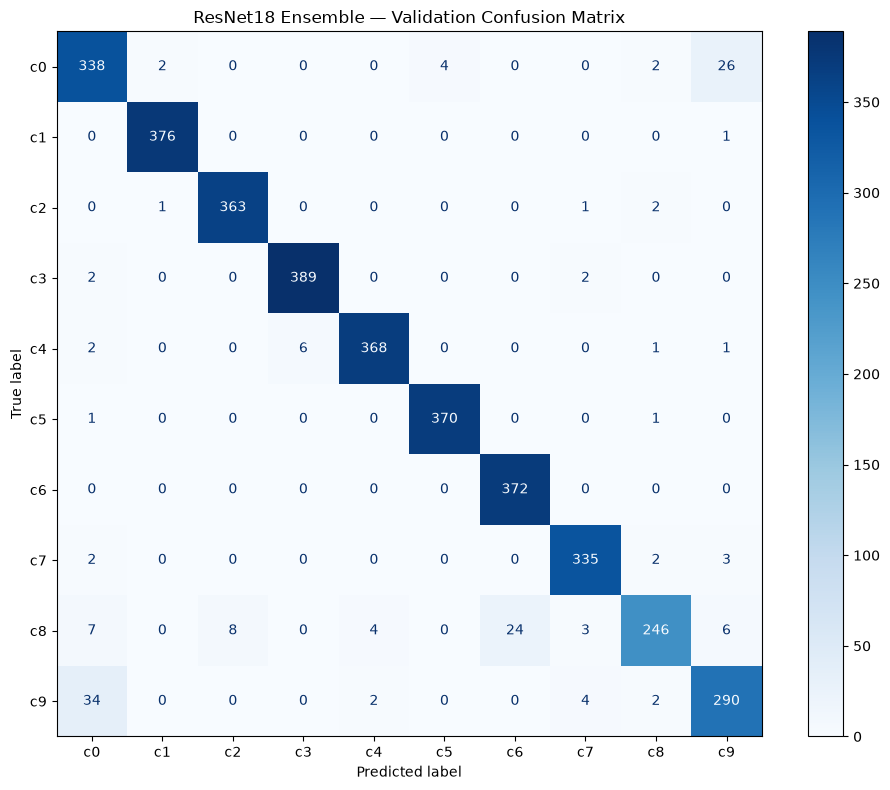

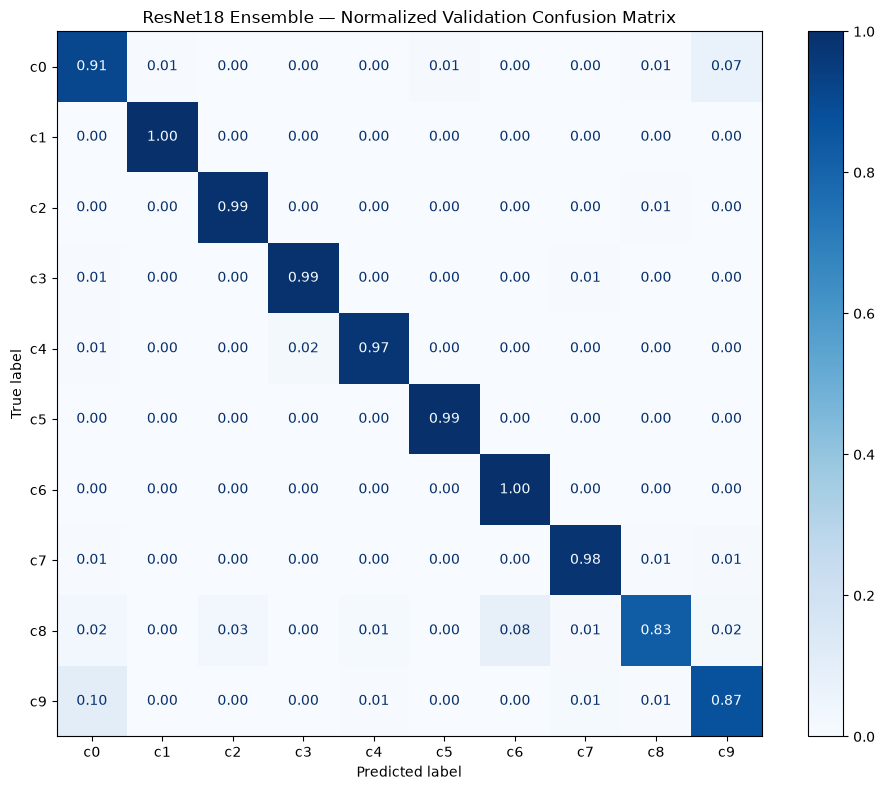

c0 recall: 90.86%
c8 recall: 82.55%
c9 recall: 87.35%

Both confusion matrices saved!
Location: ../results/deep_learning/driver_based/resnet18/ensemble_384x288_512x384


In [4]:
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# ============================================================
# 1. RESULT DIRECTORY
# ============================================================

ensemble_dir = (
    ROOT / "results/deep_learning/driver_based/"
    "resnet18/ensemble_384x288_512x384"
)

ensemble_dir.mkdir(parents=True, exist_ok=True)

class_names = [f"c{i}" for i in range(10)]

# Verify that ensemble inference has already been completed
assert len(y_true) == 3603
assert len(pred_ensemble) == 3603


# ============================================================
# 2. CONFUSION MATRIX — RAW COUNTS
# ============================================================

cm = confusion_matrix(
    y_true,
    pred_ensemble,
    labels=list(range(10))
)

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("ResNet18 Ensemble — Validation Confusion Matrix")

plt.tight_layout()

plt.savefig(
    ensemble_dir / "confusion_matrix_counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 3. NORMALIZED CONFUSION MATRIX
# ============================================================

cm_normalized = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f"
)

ax.set_title(
    "ResNet18 Ensemble — Normalized Validation Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    ensemble_dir / "confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 4. CHECK DIFFICULT CLASSES
# ============================================================

for class_id in [0, 8, 9]:
    recall = cm[class_id, class_id] / cm[class_id].sum()

    print(f"c{class_id} recall: {recall:.2%}")

print("\nBoth confusion matrices saved!")
print("Location:", ensemble_dir)

## 6. Ensemble — Visual Validation Predictions

Visualize predictions from our multi-resolution ResNet18 ensemble.

- 6 correctly classified validation images
- 6 incorrectly classified validation images
- Show actual class, predicted class, and confidence

Goal: Understand the strengths and remaining weaknesses
of the ensemble.

Device: cuda
Both checkpoints found!
Validation images: 3603
Validation drivers: 4

Running ResNet18 384×288...
Completed in 8.89s

Running ResNet18 512×384...
Completed in 12.33s

All 3,603 images verified!

RESNET18 ENSEMBLE — FULL VALIDATION INFERENCE
Validation images: 3603
Accuracy: 0.9567 (95.67%)
Macro-F1: 0.9540 (95.40%)
Inference time: 21.22s

PER-CLASS CLASSIFICATION REPORT
              precision    recall  f1-score   support

          c0       0.88      0.91      0.89       372
          c1       0.99      1.00      0.99       377
          c2       0.98      0.99      0.98       367
          c3       0.98      0.99      0.99       393
          c4       0.98      0.97      0.98       378
          c5       0.99      0.99      0.99       372
          c6       0.94      1.00      0.97       372
          c7       0.97      0.98      0.98       342
          c8       0.96      0.83      0.89       298
          c9       0.89      0.87      0.88       332

    accuracy     

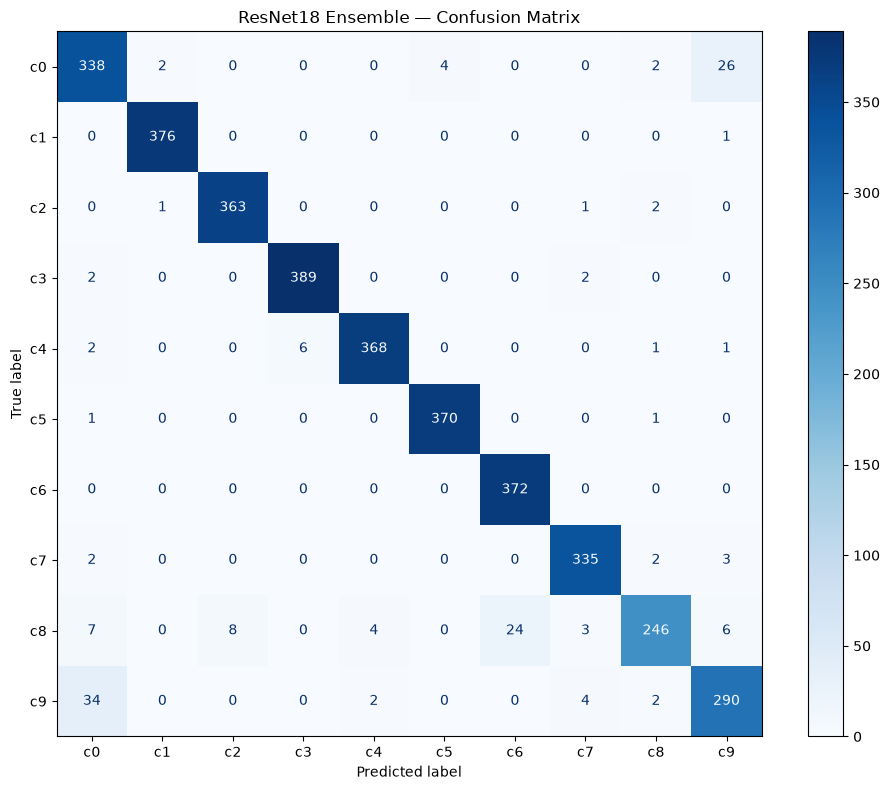

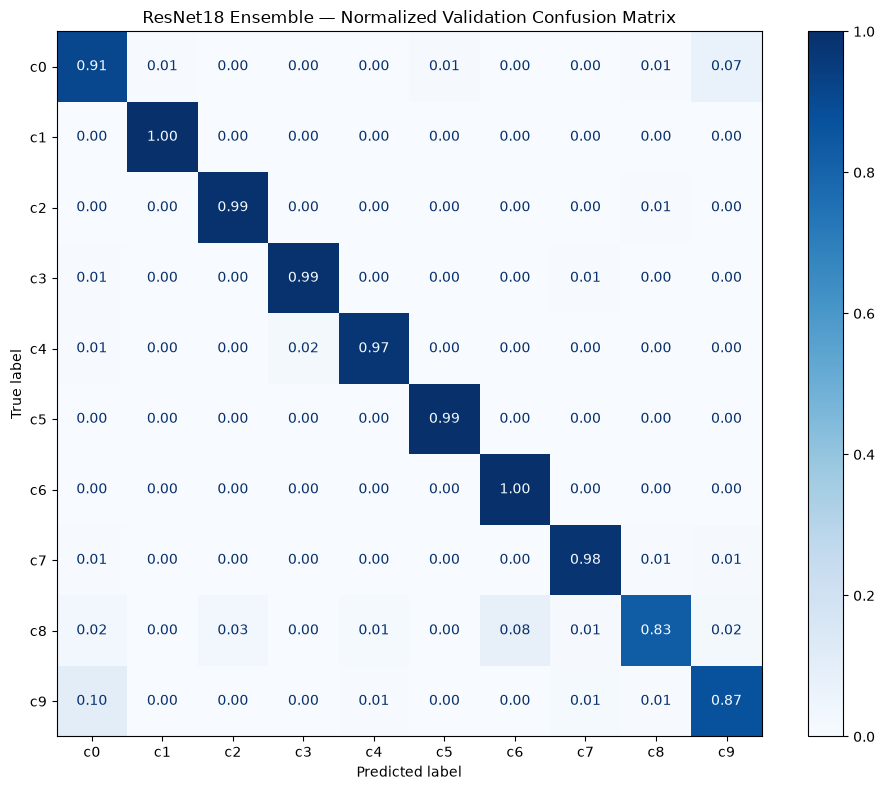


FULL ENSEMBLE INFERENCE COMPLETED
Results saved: ../results/deep_learning/driver_based/resnet18/ensemble_384x288_512x384


In [10]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import json

from pathlib import Path
from PIL import Image

from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)


# ============================================================
# 2. CONFIGURATION
# ============================================================

ROOT = Path("..")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE = 32

image_root = ROOT / "data/raw/imgs/train"

checkpoint_384 = (
    ROOT / "models/deep_learning/driver_based/"
    "resnet18/resolution_384x288/best_model.pt"
)

checkpoint_512 = (
    ROOT / "models/deep_learning/driver_based/"
    "resnet18/resolution_512x384/best_model.pt"
)

ensemble_dir = (
    ROOT / "results/deep_learning/driver_based/"
    "resnet18/ensemble_384x288_512x384"
)

ensemble_dir.mkdir(parents=True, exist_ok=True)

assert checkpoint_384.exists()
assert checkpoint_512.exists()

print("Device:", device)
print("Both checkpoints found!")


# ============================================================
# 3. LOAD VALIDATION DATASET
# ============================================================

val_df = pd.read_csv(
    ROOT / "data/splits/driver_based/val.csv"
).reset_index(drop=True)

assert len(val_df) == 3603

print("Validation images:", len(val_df))
print("Validation drivers:", val_df["subject"].nunique())


# ============================================================
# 4. CREATE VALIDATION DATASET
# ============================================================

class DriverDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        row = self.data.iloc[idx]

        image_path = (
            image_root /
            row["classname"] /
            row["img"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        label = int(row["classname"][1:])

        return image, label


# ============================================================
# 5. CREATE DATALOADERS FOR BOTH RESOLUTIONS
# ============================================================

def create_loader(width, height):

    transform = transforms.Compose([
        transforms.Resize((height, width)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    dataset = DriverDataset(val_df, transform)

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )


loader_384 = create_loader(384, 288)
loader_512 = create_loader(512, 384)


# ============================================================
# 6. MODEL LOADING AND INFERENCE FUNCTION
# ============================================================

def run_inference(checkpoint_path, loader):

    # Create ResNet18 architecture
    model = models.resnet18(weights=None)

    # Replace classifier
    model.fc = nn.Linear(
        model.fc.in_features,
        10
    )

    # Load our fine-tuned weights
    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )
    )

    model = model.to(device)
    model.eval()

    all_probs = []
    all_labels = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            all_probs.append(
                probabilities.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    del model

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return (
        np.concatenate(all_probs),
        np.array(all_labels),
        elapsed
    )


# ============================================================
# 7. RUN BOTH MODELS ON ALL VALIDATION IMAGES
# ============================================================

print("\nRunning ResNet18 384×288...")

probs_384, labels_384, time_384 = run_inference(
    checkpoint_384,
    loader_384
)

print(f"Completed in {time_384:.2f}s")

print("\nRunning ResNet18 512×384...")

probs_512, labels_512, time_512 = run_inference(
    checkpoint_512,
    loader_512
)

print(f"Completed in {time_512:.2f}s")


# ============================================================
# 8. VERIFY IMAGE ORDER
# ============================================================

assert np.array_equal(labels_384, labels_512)

y_true = labels_384

assert np.array_equal(
    y_true,
    val_df["classname"].str[1:].astype(int).to_numpy()
)

assert probs_384.shape == (3603, 10)
assert probs_512.shape == (3603, 10)

print("\nAll 3,603 images verified!")


# ============================================================
# 9. ENSEMBLE — SOFT VOTING
# ============================================================

ensemble_probs = (
    0.5 * probs_384 +
    0.5 * probs_512
)

pred_ensemble = ensemble_probs.argmax(axis=1)

confidences = ensemble_probs.max(axis=1)


# ============================================================
# 10. CALCULATE PERFORMANCE
# ============================================================

accuracy = accuracy_score(
    y_true,
    pred_ensemble
)

macro_f1 = f1_score(
    y_true,
    pred_ensemble,
    labels=list(range(10)),
    average="macro",
    zero_division=0
)

print("\n" + "=" * 55)
print("RESNET18 ENSEMBLE — FULL VALIDATION INFERENCE")
print("=" * 55)

print("Validation images:", len(y_true))

print(f"Accuracy: {accuracy:.4f} ({accuracy:.2%})")
print(f"Macro-F1: {macro_f1:.4f} ({macro_f1:.2%})")

print(f"Inference time: {time_384 + time_512:.2f}s")

print("\nPER-CLASS CLASSIFICATION REPORT")

print(
    classification_report(
        y_true,
        pred_ensemble,
        labels=list(range(10)),
        target_names=[f"c{i}" for i in range(10)],
        zero_division=0
    )
)


# ============================================================
# 11. SAVE ALL VALIDATION PREDICTIONS
# ============================================================

prediction_df = val_df.copy()

prediction_df["predicted"] = [
    f"c{x}" for x in pred_ensemble
]

prediction_df["confidence"] = confidences

prediction_df["correct"] = (
    prediction_df["classname"] ==
    prediction_df["predicted"]
)

prediction_df.to_csv(
    ensemble_dir / "validation_predictions.csv",
    index=False
)

# Save all class probabilities
np.savez_compressed(
    ensemble_dir / "validation_probabilities.npz",
    probs_384=probs_384,
    probs_512=probs_512,
    ensemble_probs=ensemble_probs,
    y_true=y_true
)

print("\nCorrect predictions:", prediction_df["correct"].sum())
print("Incorrect predictions:", (~prediction_df["correct"]).sum())


# ============================================================
# 12. DRIVER-SPECIFIC ACCURACY
# ============================================================

driver_results = (
    prediction_df
    .groupby("subject")
    .agg(
        images=("correct", "size"),
        accuracy=("correct", "mean")
    )
    .sort_values("accuracy")
)

print("\nACCURACY BY DRIVER")
print(driver_results.to_string())

driver_results.to_csv(
    ensemble_dir / "driver_accuracy.csv"
)


# ============================================================
# 13. CONFUSION MATRIX — COUNTS
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    pred_ensemble,
    labels=list(range(10)),
    display_labels=[f"c{i}" for i in range(10)],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("ResNet18 Ensemble — Confusion Matrix")

plt.tight_layout()

plt.savefig(
    ensemble_dir / "confusion_matrix_counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 14. NORMALIZED CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    pred_ensemble,
    labels=list(range(10)),
    display_labels=[f"c{i}" for i in range(10)],
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    ax=ax
)

ax.set_title(
    "ResNet18 Ensemble — Normalized Validation Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    ensemble_dir / "confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 15. SAVE FINAL RESULTS
# ============================================================

results = {
    "model": "ResNet18 Multi-Resolution Ensemble",
    "method": "50/50 probability averaging",
    "validation_images": len(y_true),
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "inference_time_seconds": float(time_384 + time_512),
    "checkpoints": {
        "384x288": str(checkpoint_384),
        "512x384": str(checkpoint_512)
    }
}

with open(ensemble_dir / "results.json", "w") as f:
    json.dump(results, f, indent=4)

print("\n" + "=" * 55)
print("FULL ENSEMBLE INFERENCE COMPLETED")
print("=" * 55)

print("Results saved:", ensemble_dir)